# Part 1 - Price Cut

**Result:** the cut clearly raised membership: +11.5 pp, about 4× the largest placebo. Revenue per customer in percentage terms did not measurably change. The dollar DiD (+\$0.37) is about twice the largest placebo, so it is suggestive at best.

**Method.** A difference-in-differences against Panem, with region and season fixed effects, and placebo cuts at four earlier dates as the reality check on its confidence interval.

The Westeros adjustment moves the DiD by at most \$0.009, 0.005 log points and 0.08 pp, which is small next to every CI.

---

## *Prompt used for AI
1. Run a DiD event study using Winter 2019 as the reference. Use historical-gap bands and add model-based confidence interval as diagnostic.
2. Run placebo tests using only pre-cut data. Each fake cut should have at least 4 pre-cut and 4 post-cut seasons.
3. Run a standard DiD to estimate the average treatment effect per customer per season, using all pre- and post-cut periods.
4. Include region and time fixed effects, and weight by customer count. I also want to add a Westeros winter adjustment because it shows 0 impression but test the results without it too.
5. Make the code modular, write the helper functions into the `utils.py`, so I can easily run everything on three metrics:
   - Revenue per customer
   - Log revenue per customer (log after aggregation)
   - Membership percentage

Have some plots functions to show band and gap cleanly. Also mark the price cut time on the plots.

*Later change: the event study and its historical-gap band were dropped. The placebo cuts now serve as the benchmark for how big an "effect" appears when nothing happened.*

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import os, sys
if Path.cwd().name == 'analysis':
    os.chdir('..')
sys.path.insert(0, os.getcwd())

import helper.utils as u

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
u.apply_style()

panel = u.load_panel('data/customer_panel.csv')
cells = u.build_cells(panel)
print(f"{len(panel):,} customer-season rows -> {len(cells)} cells "
      f"({cells['region_name'].nunique()} regions x {cells['t'].nunique()} seasons)")

6,121,068 customer-season rows -> 72 cells (6 regions x 12 seasons)


In [2]:
assert cells.groupby('region_name')['n'].nunique().eq(1).all(), 'a region has a different customer count in some season'
assert cells['treated'].eq(cells['region_name'].ne(u.CONTROL).astype(int)).all(), 'treated should be 0 for panem and 1 elsewhere'

In [3]:
# One region, all seasons: the three metrics and the flags used in the regressions
cells.loc[cells['region_name'].eq('westeros'),
          ['region_name', 't', 'n', 'members', 'revenue', 'revenue_pc', 'log_revenue_pc', 'member_pct',
           'treated', 'post', 'treated_post', 'westeros_winter']].round(3)

,region_name,t,n,members,revenue,revenue_pc,log_revenue_pc,member_pct,treated,post,treated_post,westeros_winter
60,westeros,0,101594,2448,29256,0.288,-1.245,2.410,1,0,0,1
61,westeros,1,101594,8614,111126,1.094,0.090,8.479,1,0,0,0
62,westeros,2,101594,10065,121729,1.198,0.181,9.907,1,0,0,0
63,westeros,3,101594,11130,134739,1.326,0.282,10.955,1,0,0,0
64,westeros,4,101594,12435,151472,1.491,0.399,12.240,1,0,0,1
65,westeros,5,101594,9839,115858,1.140,0.131,9.685,1,0,0,0
66,westeros,6,101594,19423,251610,2.477,0.907,19.118,1,0,0,0
67,westeros,7,101594,18732,224184,2.207,0.791,18.438,1,0,0,0
68,westeros,8,101594,23506,292337,2.878,1.057,23.137,1,0,0,1
69,westeros,9,101594,25454,229855,2.262,0.816,25.055,1,1,1,0


## The DiD regression, shared by all metrics

`treated_post` = 1 for a cut region from spring 2019 onwards. It was already built in `build_cells`.

$$y_{rt} = \alpha_r + \lambda_t + \delta\,\text{treated\_post}_{rt} \;+\; \gamma\,\text{westeros\_winter}_{rt} + \varepsilon_{rt}$$

WLS on the 72 cells, weighted by the region's customer count, with robust (HC1) standard errors. $\delta$ is the average effect per customer per season, and its 95% CI comes from the model. The $\gamma$ term is included "with the Westeros adjustment" and dropped "without".

**Placebo dates.** Keep only the nine pre-cut seasons (winter 2017 – winter 2019). A fake cut at season *k* needs at least 3 seasons before *k*, and at least 3 from *k* through winter 2019.

In [4]:
pre_cells = cells[cells['t'] < u.CUT_T].copy()
pre_periods = sorted(pre_cells['t'].unique())
fake_cuts = [k for k in pre_periods
             if sum(p < k for p in pre_periods) >= 3 and sum(p >= k for p in pre_periods) >= 3]

# Results are stored per metric, then per Westeros setting (True = with the adjustment)
placebos, dids = {}, {}

pd.DataFrame({'fake cut': [u.period_label(k) for k in fake_cuts],
              'seasons before': [sum(p < k for p in pre_periods) for k in fake_cuts],
              'seasons from the fake cut to Win 2019': [sum(p >= k for p in pre_periods) for k in fake_cuts]})

,fake cut,seasons before,seasons from the fake cut to Win 2019
0,Fall 2017,3,6
1,Win 2018,4,5
2,Spr 2018,5,4
3,Sum 2018,6,3


---

Each metric below runs the same two steps:

1. **Standard DiD**, with and without the Westeros adjustment, with the model's 95% CI.
2. **Placebos**: the same DiD on pre-cut data only, pretending the cut happened at each of the four fake dates.

**How to read them.** The model CI treats the 72 cells as independent observations. It misses Panem's own shocks, which hit every comparison at once because Panem is the only control, and it misses that the gap is correlated from season to season. The placebos show how large an "effect" appears when nothing happened, so the real DiD is compared with the **spread of the placebo estimates**, not with the placebos' own CIs.

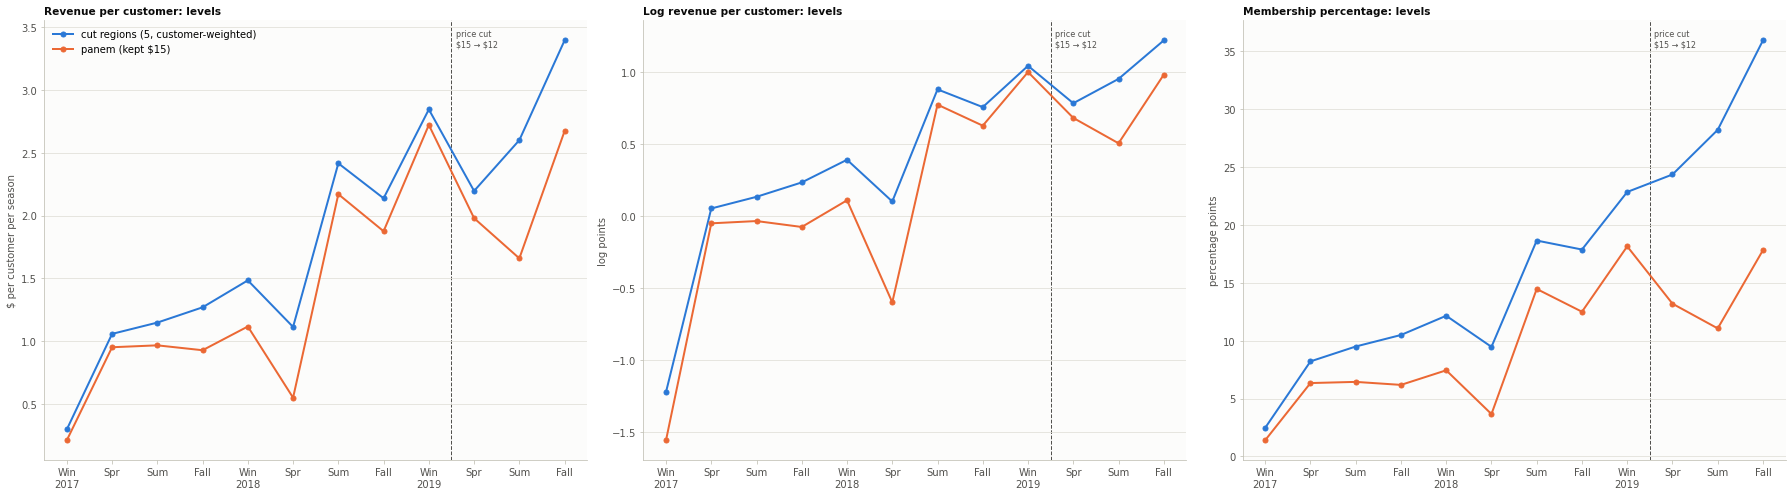

In [5]:
# Levles for all 3 metrics
fig, axes = plt.subplots(1, 3, figsize=(25, 7))
for ax, y in zip(axes, ['revenue_pc', 'log_revenue_pc', 'member_pct']):
    u.plot_levels(cells, y, ax=ax)
for ax in axes[1:]:
    ax.get_legend().remove()
plt.tight_layout()
plt.show()

## 1. Revenue per customer (`revenue_pc`, \$ per customer per season)

### 1.1 Standard DiD: average effect per customer per season

In [6]:
y = 'revenue_pc'
rows = {}
for adj in (True, False):
    fit = u.fit_wls(cells, y, ['treated_post'], westeros_adj=adj)
    rows[adj] = {**u.coef_table(fit, ['treated_post']).iloc[0],
                 'westeros_winter_coef': fit.params.get('westeros_winter', np.nan)}
dids[y] = pd.DataFrame(rows).T.rename_axis('westeros_adj')

print(f"Westeros adjustment changes the DiD by {dids[y].loc[True, 'estimate'] - dids[y].loc[False, 'estimate']:+.3f}")
dids[y].round(3)

Westeros adjustment changes the DiD by -0.009


,estimate,se,ci_low,ci_high,p_value,westeros_winter_coef
westeros_adj,,,,,,
True,0.365,0.152,0.067,0.663,0.016,-0.097
False,0.374,0.151,0.078,0.670,0.013,NaN


### 1.2 Placebos vs the real cut

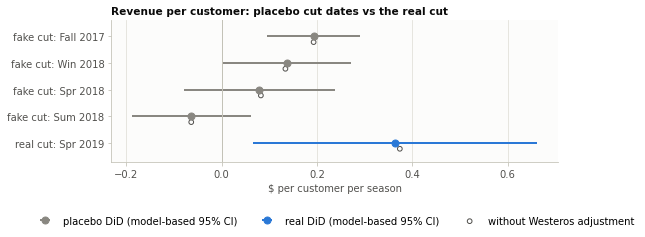

In [7]:
y = 'revenue_pc'
rows = []
for k in fake_cuts:
    d = pre_cells.assign(fake_post=pre_cells['treated'] * pre_cells['t'].ge(k).astype(int))
    for adj in (True, False):
        fit = u.fit_wls(d, y, ['fake_post'], westeros_adj=adj)
        rows.append({'cut': f'fake cut: {u.period_label(k)}', 'westeros_adj': adj,
                     **u.coef_table(fit, ['fake_post']).iloc[0]})
placebos[y] = pd.DataFrame(rows)

u.plot_placebos(placebos[y], dids[y], y)
plt.show()

**Reading: revenue per customer (\$)**

* **DiD.** +\$0.365 per customer per season, model CI [+0.07, +0.66]. Without the Westeros adjustment it is +\$0.374.
* **Placebos.** +0.19, +0.14, +0.08 and −0.06 at the four fake dates. The real DiD is about twice the largest, so it is suggestive, not clear.
* **Caution.** The pre-cut dollar gap was unstable: it rose from \$0.09 in early 2017 to \$0.56 in spring 2018, then fell back to \$0.12 by winter 2019.

## 2. Log revenue per customer (`log_revenue_pc`, log points)

### 2.1 Standard DiD: average effect per customer per season

In [8]:
y = 'log_revenue_pc'
rows = {}
for adj in (True, False):
    fit = u.fit_wls(cells, y, ['treated_post'], westeros_adj=adj)
    rows[adj] = {**u.coef_table(fit, ['treated_post']).iloc[0],
                 'westeros_winter_coef': fit.params.get('westeros_winter', np.nan)}
dids[y] = pd.DataFrame(rows).T.rename_axis('westeros_adj')

print(f"Westeros adjustment changes the DiD by {dids[y].loc[True, 'estimate'] - dids[y].loc[False, 'estimate']:+.3f}")
dids[y].round(3)

Westeros adjustment changes the DiD by -0.005


,estimate,se,ci_low,ci_high,p_value,westeros_winter_coef
westeros_adj,,,,,,
True,0.015,0.087,-0.156,0.186,0.862,-0.057
False,0.021,0.086,-0.147,0.189,0.810,NaN


### 2.2 Placebos vs the real cut

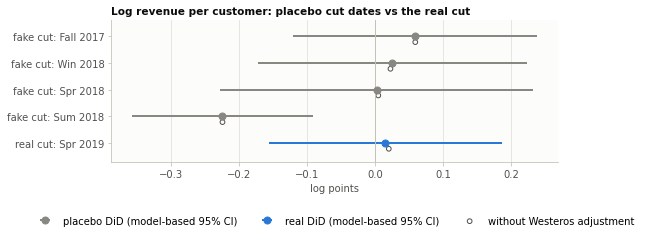

In [9]:
y = 'log_revenue_pc'

rows = []
for k in fake_cuts:
    d = pre_cells.assign(fake_post=pre_cells['treated'] * pre_cells['t'].ge(k).astype(int))
    for adj in (True, False):
        fit = u.fit_wls(d, y, ['fake_post'], westeros_adj=adj)
        rows.append({'cut': f'fake cut: {u.period_label(k)}', 'westeros_adj': adj,
                     **u.coef_table(fit, ['fake_post']).iloc[0]})
placebos[y] = pd.DataFrame(rows)
placebos[y].round(3)

u.plot_placebos(placebos[y], dids[y], y)
plt.show()

**Reading: log revenue per customer**

* **DiD.** +0.015 log points (≈ +1.5%), model CI [−0.16, +0.19]. Without the Westeros adjustment it is +0.021.
* **Placebos.** +0.06, +0.03, +0.00 and −0.22. The real DiD sits inside their range.
* **Takeaway.** There is no detectable change in revenue per customer in percentage terms.

## 3. Membership percentage (`member_pct`, percentage points)

### 3.1 Standard DiD: average effect per customer per season

In [10]:
y = 'member_pct'
rows = {}
for adj in (True, False):
    fit = u.fit_wls(cells, y, ['treated_post'], westeros_adj=adj)
    rows[adj] = {**u.coef_table(fit, ['treated_post']).iloc[0],
                 'westeros_winter_coef': fit.params.get('westeros_winter', np.nan)}
dids[y] = pd.DataFrame(rows).T.rename_axis('westeros_adj')

print(f"Westeros adjustment changes the DiD by {dids[y].loc[True, 'estimate'] - dids[y].loc[False, 'estimate']:+.3f}")
dids[y].round(3)

Westeros adjustment changes the DiD by -0.076


,estimate,se,ci_low,ci_high,p_value,westeros_winter_coef
westeros_adj,,,,,,
True,11.509,1.549,8.474,14.544,0.0,-0.803
False,11.585,1.539,8.568,14.602,0.0,NaN


### 3.2 Placebos vs the real cut

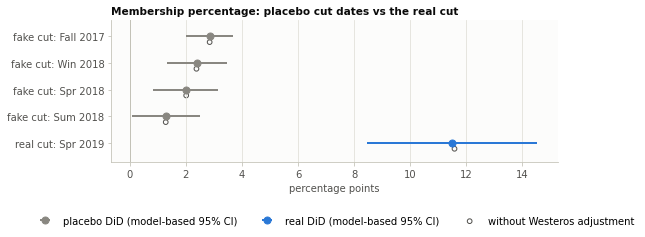

In [11]:
y = 'member_pct'

rows = []
for k in fake_cuts:
    d = pre_cells.assign(fake_post=pre_cells['treated'] * pre_cells['t'].ge(k).astype(int))
    for adj in (True, False):
        fit = u.fit_wls(d, y, ['fake_post'], westeros_adj=adj)
        rows.append({'cut': f'fake cut: {u.period_label(k)}', 'westeros_adj': adj,
                     **u.coef_table(fit, ['fake_post']).iloc[0]})
placebos[y] = pd.DataFrame(rows)
placebos[y].round(3)

u.plot_placebos(placebos[y], dids[y], y)
plt.show()

**Reading: membership percentage**

* **DiD.** +11.5 pp, model CI [+8.5, +14.5]. Without the Westeros adjustment it is +11.6 pp.
* **Placebos.** +2.8, +2.4, +2.0 and +1.3 pp. All positive, so there is a small pre-trend, but the real DiD is about 4× the largest.
* **Caution.** Panem's own member share fell from 18.2% to 11.1% between winter and summer 2019 with no price change (levels plot above). Part of the post-cut gap is Panem's drop, not the cut regions' rise.

## 4. All three metrics side by side

In [12]:
rows = {}
for y, meta in u.METRICS.items():
    d = dids[y]
    pl = placebos[y][placebos[y]['westeros_adj']]
    largest = pl['estimate'].abs().max()
    rows[meta['label']] = {
        'DiD (with Westeros adj.)': round(d.loc[True, 'estimate'], 3),
        'model 95% CI': f"[{d.loc[True, 'ci_low']:+.3f}, {d.loc[True, 'ci_high']:+.3f}]",
        'placebo DiDs (' + ', '.join(c.replace('fake cut: ', '') for c in pl['cut']) + ')':
            ', '.join(f"{v:+.3f}" for v in pl['estimate']),
        'DiD / largest placebo': f"{d.loc[True, 'estimate'] / largest:.1f}×",
        'DiD without Westeros adj.': round(d.loc[False, 'estimate'], 3),
    }
pd.DataFrame(rows).T

,DiD (with Westeros adj.),model 95% CI,"placebo DiDs (Fall 2017, Win 2018, Spr 2018, Sum 2018)",DiD / largest placebo,DiD without Westeros adj.
Revenue per customer,0.365,"[+0.067, +0.663]","+0.193, +0.138, +0.079, -0.064",1.9×,0.374
Log revenue per customer,0.015,"[-0.156, +0.186]","+0.059, +0.026, +0.003, -0.224",0.1×,0.021
Membership percentage,11.509,"[+8.474, +14.544]","+2.848, +2.409, +1.991, +1.281",4.0×,11.585
